# Data Visualization: Turning Retail Sales Data into a Visual Story

**Name:** Anish Kumar &nbsp;&nbsp; **Roll number:** 2026M01410002 &nbsp;&nbsp; **GitHub:** https://github.com/AnishWebDesigner/Data-Analyst-Project

Data Analyst Training Program, Mini Project 2

---

The sales and marketing team of a retail company wants to see patterns at a glance instead of reading a spreadsheet. In this notebook I load two years of their orders, clean up the obvious problems, and draw 13 charts. Each chart answers one question and has a short caption in plain business language.

The charts are not written inside the notebook. They live in `src/visualizations.py`, so the notebook, the PDF report and the Streamlit dashboard all use exactly the same code. The notebook only calls them and shows the results.

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")                      # so the notebook can import the project code

import matplotlib.pyplot as plt
import pandas as pd

import config
from src.data_cleaning import load_raw, audit, clean, check
from src.visualizations import CHARTS, CHAPTERS, CHART_FUNCTIONS
from src.captions import build_captions

pd.set_option("display.float_format", "{:,.2f}".format)
config.CHART_DIR.mkdir(parents=True, exist_ok=True)
print("Student:", config.STUDENT_NAME, "|", config.ROLL_NO)

Student: Anish Kumar | 2026M01410002


## 2. Loading the data and cleaning it

In [2]:
raw = load_raw(config.RAW_CSV)
print(f"{raw.shape[0]:,} rows and {raw.shape[1]} columns")
raw.head()

7,084 rows and 24 columns


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.00,Male,"62,828.52",West,Gujarat,Surat,Consumer,Grocery,Honey Jar,3,887.94,0.32,"1,811.40","1,204.47",606.93,Debit Card,Standard,3.00,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.00,Male,"50,952.64",North,Haryana,Gurugram,Home Office,Electronics,USB-C Hub,2,"14,309.96",0.18,"23,468.33","17,137.06","6,331.27",Credit Card,Standard,3.00,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.00,Male,"60,476.00",East,Jharkhand,Ranchi,Consumer,Clothing,Winter Jacket,4,710.95,0.09,"2,587.86","1,577.83","1,010.03",Debit Card,Express,3.00,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.00,Male,"41,516.94",West,Gujarat,Surat,Home Office,Grocery,Olive Oil 1L,4,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.00,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.00,Female,"95,727.49",north,Haryana,Gurugram,Consumer,Electronics,Laptop Stand,1,"10,542.13",0.21,"8,328.28","5,528.47","2,799.81",UPI,Express,1.00,Low,No


The brief says the file is messy on purpose, so before drawing anything I counted what is wrong with it.

In [3]:
found = audit(raw)
problems = pd.DataFrame([
    ("Repeated Transaction_IDs", found["duplicate_ids"], f"only {found['exact_duplicates']} are exact copies; the rest differ in how the date is written"),
    ("Rows with dates not in ISO style", found["rows_with_odd_dates"], "four different date styles in the file"),
    ("Spellings used for Gender", found["gender_labels"], "should be 2"),
    ("Labels used for Region", found["region_labels"], "should be 4"),
    ("Impossible ages", found["impossible_ages"], "values like -12, 150, 180 and 999"),
    ("Missing ages", found["missing_age"], "can be taken from the same customer's other orders"),
    ("Impossible discounts", found["impossible_discounts"], "outside 0 to 0.5"),
    ("Missing discounts", found["missing_discount"], "can be worked out from Sales"),
    ("Incomes ten times too high", found["income_spikes"], "the same customer has a normal income on other orders"),
    ("Missing incomes", found["missing_income"], "taken from the same customer where possible"),
    ("Missing ratings", found["missing_rating"], "left empty, a rating cannot be guessed"),
    ("Missing delivery dates", found["missing_delivery_date"], "left empty, a date cannot be guessed"),
], columns=["Problem", "Count", "Comment"])
problems

,Problem,Count,Comment
0,Repeated Transaction_IDs,84,only 61 are exact copies; the rest differ in how the date is written
1,Rows with dates not in ISO style,483,four different date styles in the file
2,Spellings used for Gender,8,should be 2
3,Labels used for Region,12,should be 4
4,Impossible ages,6,"values like -12, 150, 180 and 999"
5,Missing ages,142,can be taken from the same customer's other orders
6,Impossible discounts,6,outside 0 to 0.5
7,Missing discounts,71,can be worked out from Sales
8,Incomes ten times too high,9,the same customer has a normal income on other orders
9,Missing incomes,253,taken from the same customer where possible


Two of these needed a closer look.

**Dates.** The file mixes `2024-07-22`, `22/07/2024`, `07-22-2024` and `22-Jul-2024`. A date such as `05-03-2024` could be 5 March or 3 May. I checked the largest number in each position: for the slash dates the first number goes up to 31 and the second stops at 12, so they are day-first. For the dash dates it is the other way round, so they are month-first. Reading the dash dates the wrong way would give delivery times of up to 275 days.

**Discount.** Sales already has the discount built in (`Sales = Quantity x Unit_Price x (1 - Discount)`), so a missing or impossible discount can be worked out exactly instead of guessed.

In [4]:
df = clean(raw)
print(f"Rows: {len(raw):,} -> {len(df):,}")
pd.DataFrame({"Rule": list(check(df)), "Passed": ["yes" if ok else "NO" for ok in check(df).values()]})

Rows: 7,084 -> 7,000


,Rule,Passed
0,one row per Transaction_ID,yes
1,"no empty Age, Income or Discount",yes
2,Age between 18 and 100,yes
3,Discount between 0 and 0.5,yes
4,Sales = Quantity x Unit_Price x (1 - Discount),yes
5,Profit = Sales - Cost,yes
6,no delivery before the order,yes
7,2 genders and 4 regions,yes
8,largest income is realistic,yes


After cleaning there are 7,000 unique orders and every rule holds, including the two formulas for Sales and Profit.

## 3. Captions

In [5]:
captions = build_captions(df)       # each caption is worked out from the data, so it always matches its chart
print(len(captions), "captions ready")

13 captions ready


## 4. The charts

I put them in an order that tells a story: first how sales moved, then where the money is made, then who the customers are, then what drives order value and profit, then the combined heatmap, and finally returns and delivery.

Colours mean the same thing on every chart. Navy is the normal colour, teal is the leading group and coral is the point I am making (the weakest region, unhappy customers, the Same-Day mode).

In [6]:
def show(key, number):
    fig = CHART_FUNCTIONS[key](df)
    fig.savefig(config.CHART_DIR / f"{key}.png", dpi=170, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Figure {number}")

### Chapter 1: The big picture: how sales moved over two years

**Figure 1: Line chart**

Figure 1


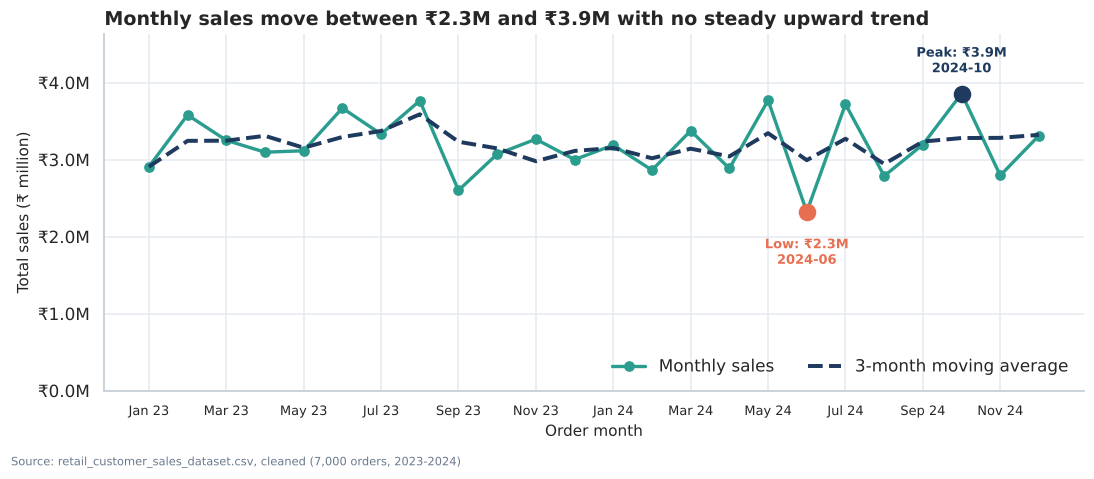

In [7]:
show("01_monthly_sales_line", 1)

> Sales came to ₹38.7M in 2023 and ₹38.1M in 2024, a change of -1.5%, and the 3-month average stays between ₹2.9M and ₹3.6M. The highest month (₹3.9M, Oct 2024) and the lowest (₹2.3M, Jun 2024) look like one-off swings, not a season that comes back every year. Growth will have to come from new customers or products, because timing campaigns will not help much.

### Chapter 2: Where the money is made: regions and products

**Figure 2: Bar chart**

Figure 2


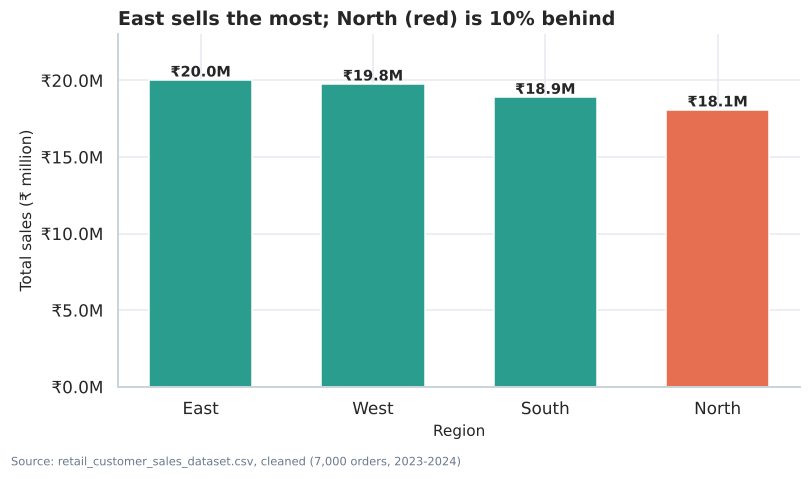

In [8]:
show("02_sales_by_region_bar", 2)

> East sells the most at ₹20.0M and North the least at ₹18.1M, which is 10% lower. North has 5% fewer orders and a 5% smaller average order, so the gap is modest. It is the first place to look for extra volume, but none of the four regions is in trouble.

**Figure 3: Bar chart**

Figure 3


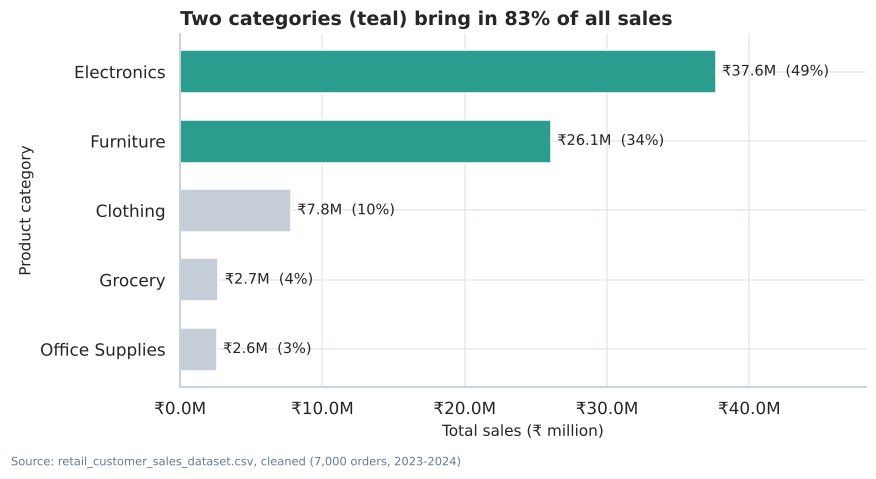

In [9]:
show("03_sales_by_category_bar", 3)

> Electronics (₹37.6M, 49%) and Furniture (₹26.1M, 34%) together bring in 83% of sales, while Office Supplies and Grocery add only 7%. An average Furniture order is worth about 17 times an average Grocery order. Stock, delivery and service quality should be protected first in the two leading categories.

### Chapter 3: Who the customers are

**Figure 4: Histogram**

Figure 4


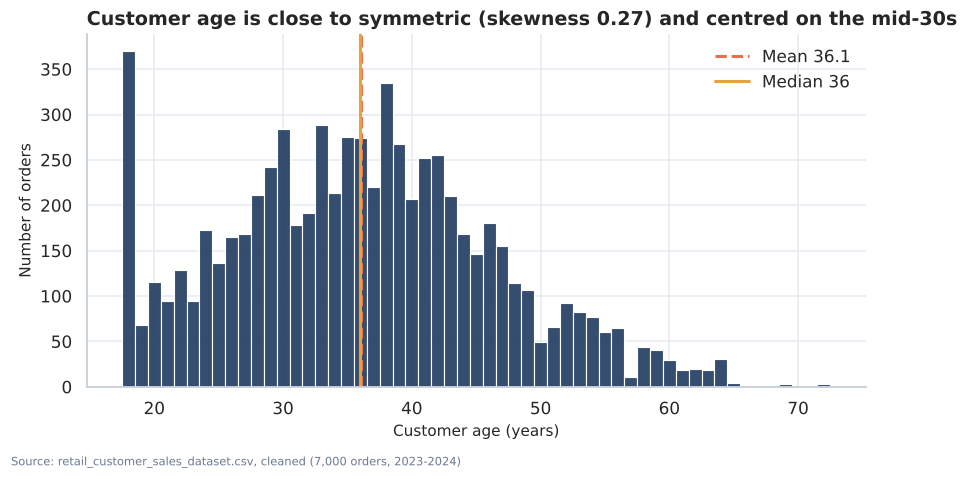

In [10]:
show("04_age_histogram", 4)

> Customers cluster around age 36 (mean 36.1, median 36) with a gentle tail up to 72, and a skewness of 0.27 means the shape is close to symmetric. The tall bar at 18 (5% of customers) looks like a lower limit in the source system rather than a real group of 18-year-olds. Half of the orders come from customers aged 29 to 43, which is the natural target for campaigns.

**Figure 5: Histogram**

Figure 5


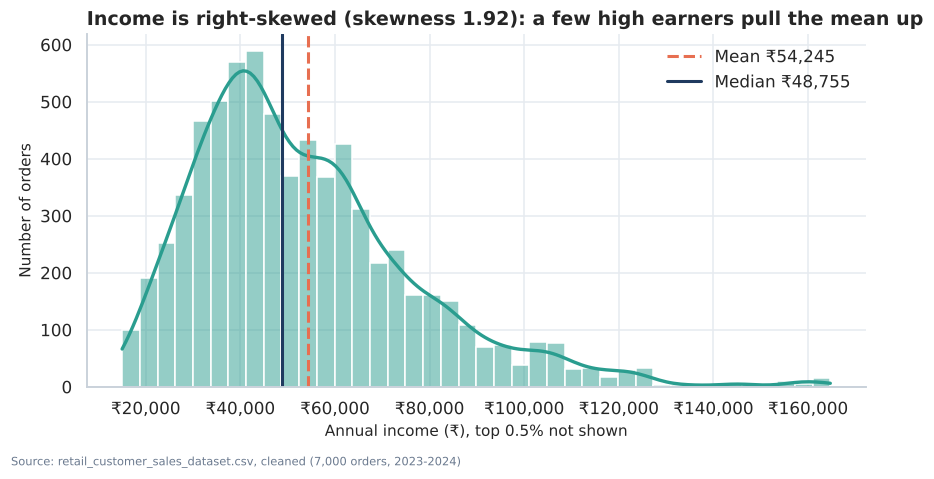

In [11]:
show("05_income_histogram", 5)

> Half of the orders come from customers earning between ₹37,072 and ₹65,690 a year, but a long right tail reaching ₹286,876 pulls the mean (₹54,245) above the median (₹48,755), with skewness at 1.92. The median is the fairer description of a typical customer. Income does not predict how much people spend, as the correlation heatmap shows.

**Figure 6: Donut chart**

Figure 6


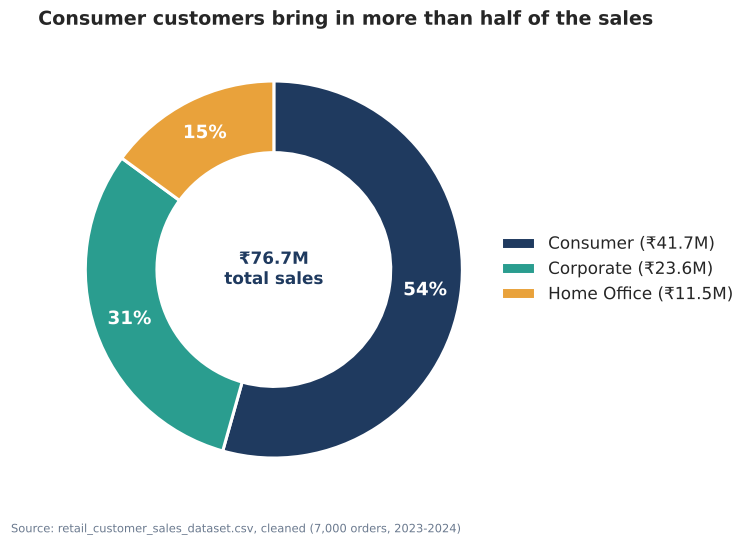

In [12]:
show("06_segment_share_donut", 6)

> Consumer customers generate 54% of sales (₹41.7M), Corporate 31% and Home Office 15%. Corporate orders are hardly bigger than consumer orders (₹11,141 against ₹10,864), so each share just follows the number of orders. Growing the business segments would need more orders, not larger ones.

### Chapter 4: What drives order value and profit

**Figure 7: Box plot**

Figure 7


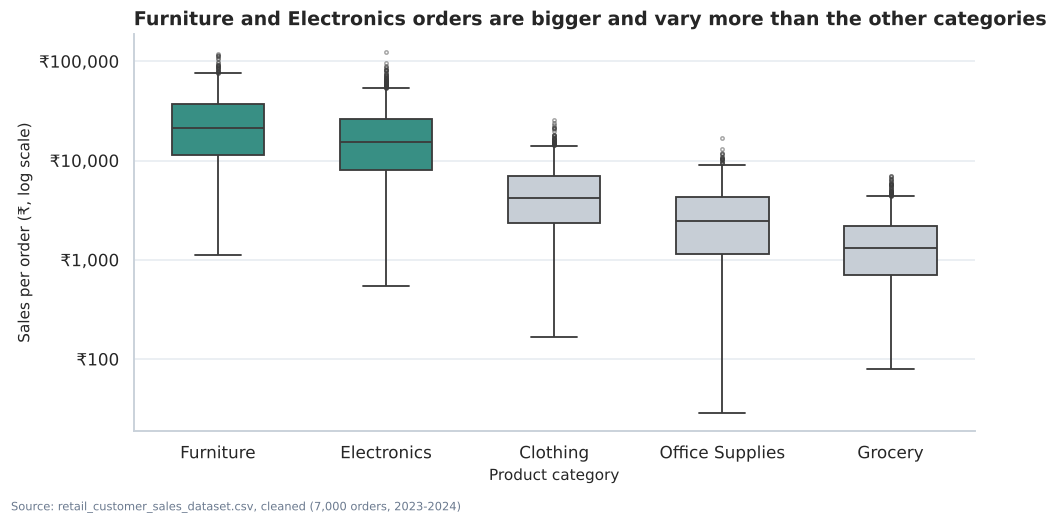

In [13]:
show("07_sales_by_category_box", 7)

> The median Furniture order is ₹21,490 and the median Electronics order ₹15,451, against ₹1,324 for Grocery, which is a 16-fold difference. These two categories also have the widest boxes and the biggest orders (up to ₹122,951), and the dots above the boxes are real large orders, not mistakes. The axis is logarithmic so that all five categories can be read, which makes the real gaps look smaller than they are.

**Figure 8: Scatter plot**

Figure 8


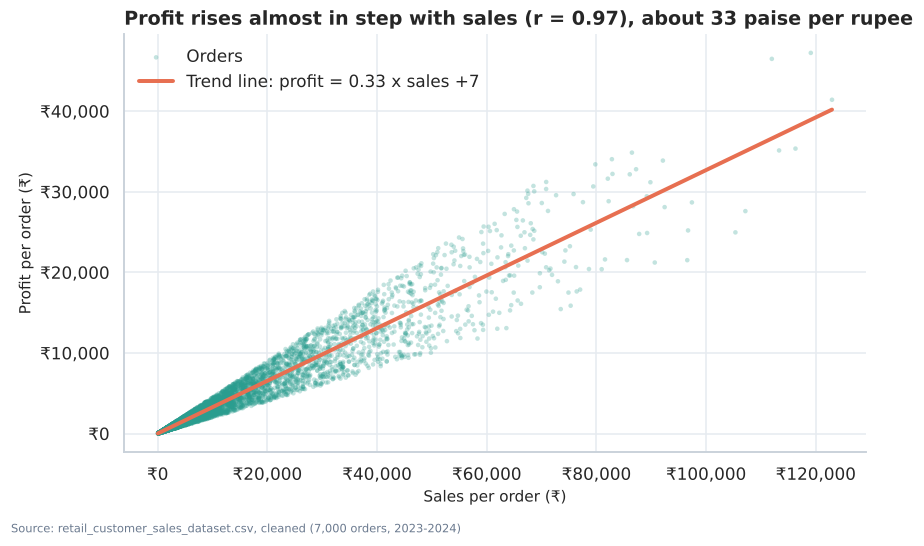

In [14]:
show("08_sales_vs_profit_scatter", 8)

> Profit is almost a fixed share of sales (r = 0.97), and the trend line says each rupee of sales leaves about 33 paise of profit. The fan shape shows that the margin on individual orders ranges from 20% to 45%, and the biggest orders earn the biggest profits. More revenue should therefore bring about the same proportion of extra profit.

**Figure 9: Scatter plot**

Figure 9


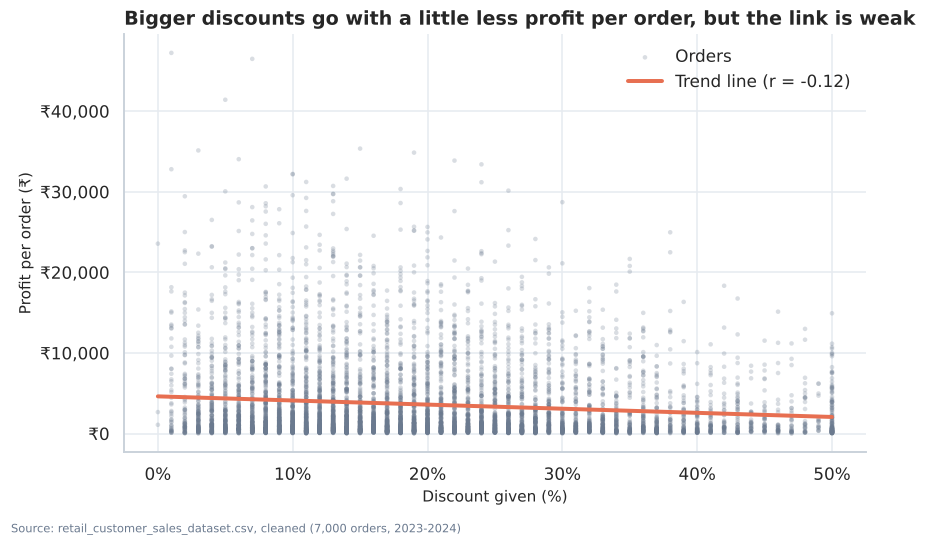

In [15]:
show("09_discount_vs_profit_scatter", 9)

> Every extra 10 points of discount goes with about ₹511 less profit per order (r = -0.12), which is a weak negative link. Discount explains only 1.5% of the variation in profit, so the straight line is a rough guide and not a rule. The size of the order matters much more for profit than the depth of the discount.

**Figure 10: Heatmap**

Figure 10


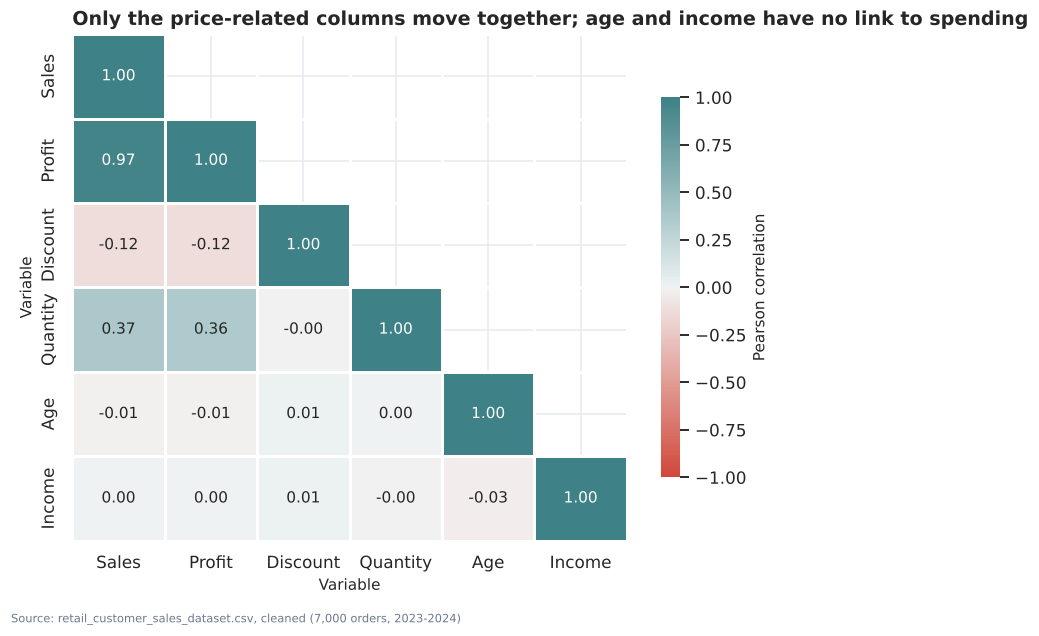

In [16]:
show("10_correlation_heatmap", 10)

> Sales and profit move almost together (r = 0.97), quantity has a moderate link with sales (0.37) and discount a weak negative one (-0.12). Age and income are close to zero against every spending column (the largest is 0.01), so who the customer is tells us very little about how much they spend. Product and price decisions are likely to matter more than targeting by age or income.

### Chapter 5: Putting category and region together

**Figure 11: Heatmap**

Figure 11


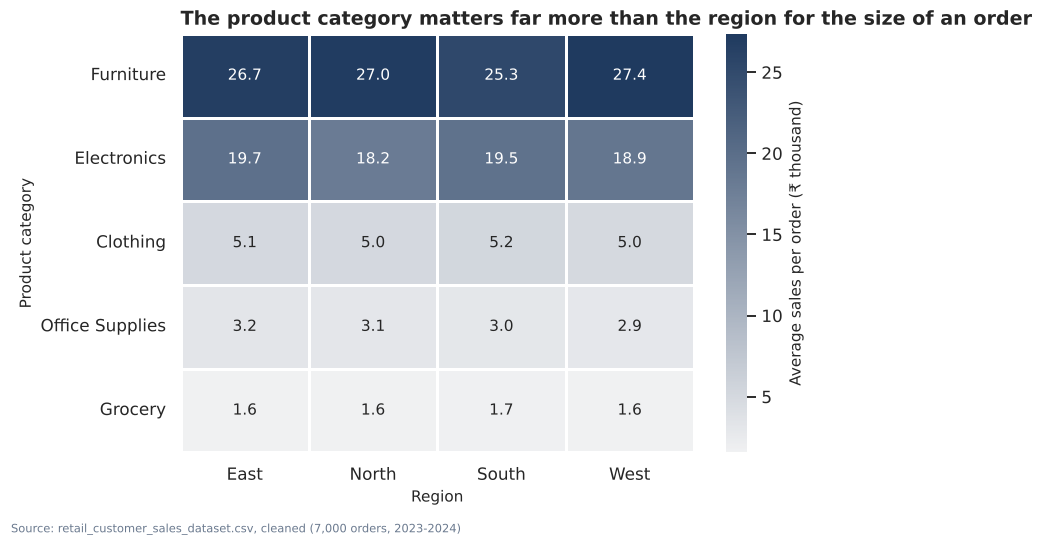

In [17]:
show("11_category_region_heatmap", 11)

> Going down a column changes the average order 18-fold, from ₹1.6K for Grocery in the North to ₹27.4K for Furniture in the West, while going across a row changes it by at most 11%. So the category mix decides the size of an order and the region hardly does. Regional targets are better set by looking at each region's category mix.

### Chapter 6: Returns and delivery

**Figure 12: Bar chart**

Figure 12


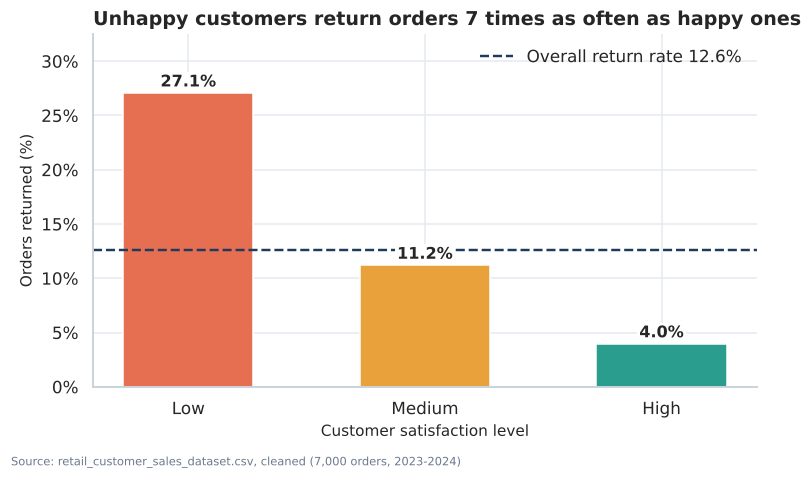

In [18]:
show("12_returns_by_satisfaction_bar", 12)

> 27.1% of low-satisfaction orders are returned, against 4.0% of high-satisfaction ones, so 7 times as often, while the overall return rate is 12.6%. Returns and unhappy customers clearly go together, although the data cannot tell us which one causes the other. Finding out what makes customers unhappy is likely to cut returns more than any action on a single category.

**Figure 13: Box plot**

Figure 13


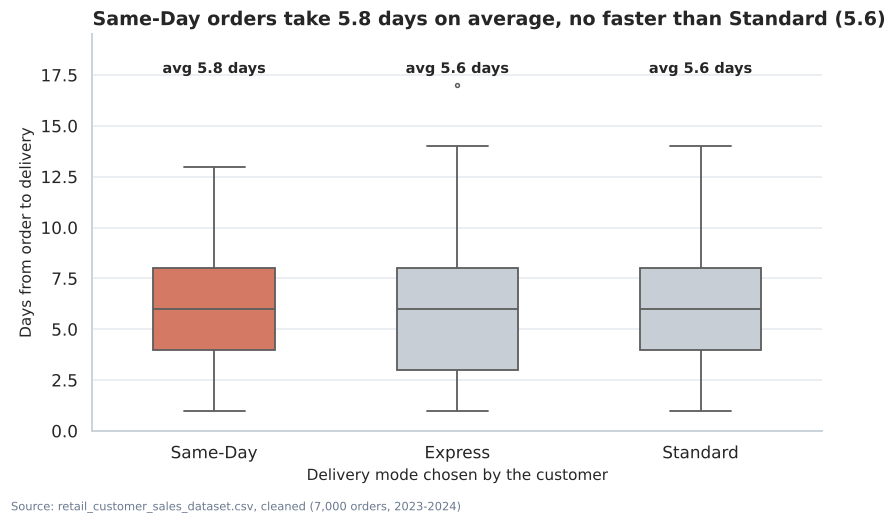

In [19]:
show("13_delivery_time_box", 13)

> Same-Day orders take 5.8 days to arrive on average, which is almost the same as Express (5.6) and Standard (5.6), and only 6.9% of them arrive within a day. The three boxes sit at the same height, so the delivery mode a customer picks makes no visible difference to the waiting time. If customers pay extra for Same-Day, they are not getting a faster service, so operations should check the delivery promise or how delivery dates are recorded.

## 5. What I take from all this

Sales are steady but not growing. They are driven by what is sold, not by where or to whom: Electronics and Furniture bring in most of the money, the regions are within about ten percent of each other, and neither age nor income says anything about spending. Profit follows sales closely, and bigger discounts cut profit per order only a little.

Two things look like real problems. Unhappy customers return seven times as many orders as happy ones, and the Same-Day delivery mode is no faster than Standard. Both are worth a closer look by the operations team.

The same charts are available as an interactive page in `dashboard/app.py` (run `streamlit run dashboard/app.py`).